# Evaluación Parcial N°1 — Deep Learning

**Asignatura:** DLY0100-DEEP LEARNING_007D_OLS    
**Framework:** TensorFlow / Keras  
**Dataset:** Fashion-MNIST  
**Integrantes:** Esteban Gamboa · Felipe Ortega  


---

## 1. Introducción

**El problema.** Tenemos fotos de prendas de vestir de 28×28 píxeles, en blanco y negro (escala de grises). La tarea es que la red mire cada foto y diga qué prenda es. Hay 10 categorías posibles: polera, pantalón, pullover, vestido, abrigo, sandalia, camisa, zapatilla, bolso y botín. A esto se le llama **clasificación**: elegir una etiqueta entre varias opciones.

**Por qué elegimos este dataset.** Teníamos tres opciones y comparamos qué tan difíciles eran para una red densa, que es la que vamos a usar:

- **MNIST** (dígitos escritos a mano) es demasiado fácil: casi todas las configuraciones llegan a cerca de 98%, así que no hay diferencias que comparar.
- **CIFAR-10** (fotos a color de objetos y animales) es demasiado difícil para una red densa: se queda cerca del 50%.
- **Fashion-MNIST** queda en el punto medio: los resultados cambian de una configuración a otra y esas diferencias se pueden explicar.

**El objetivo.** Hacer cuatro cosas:

1. Armar un **MLP** (perceptrón multicapa): una red neuronal formada por capas de neuronas conectadas entre sí.
2. Ajustar sus **hiperparámetros** (los valores que definimos nosotros antes de entrenar, como el learning rate o el tamaño del batch), probando y comparando.
3. Aplicar **regularización**: técnicas que evitan el **sobreajuste**, que es cuando la red memoriza los ejemplos de entrenamiento en vez de aprender el patrón general.
4. Evaluar con cuatro métricas: accuracy, precision, recall y F1.

**Con qué comparamos.** El repositorio oficial de Fashion-MNIST reporta 0,8833 de accuracy para un MLP y 0,835 para el desempeño humano. Son nuestras referencias para saber si el resultado es bueno.

**Antes de correrlo.** Activa la GPU en Colab (Entorno de ejecución → Cambiar tipo de entorno → T4). Con GPU demora unos 15 minutos; sin ella, unos 40.

## 2. Carga y preprocesamiento

Antes de entrenar hay que cargar los datos y dejarlos en un formato que la red pueda aprovechar bien. Esta sección lo hace paso a paso.

### 2.1 Librerías y configuración

**Qué hace el código:**

1. Importa las librerías que usamos: TensorFlow/Keras para la red, NumPy y pandas para manejar los datos, matplotlib y seaborn para los gráficos, y scikit-learn para las métricas.
2. Deja las constantes del trabajo en un solo lugar (épocas, tamaño del batch, learning rate y porcentaje de validación), para poder cambiarlas sin buscar por todo el código. `MODO_RAPIDO` sirve solo para probar que el código corre; en la entrega debe ir en `False`.
3. Define la función `fijar_semillas()`.

**Por qué existe `fijar_semillas()`:** el entrenamiento de una red tiene partes al azar; por ejemplo, los pesos con los que parte la red se sortean. Si cada modelo partiera con pesos distintos, no sabríamos si una diferencia entre dos configuraciones viene del parámetro que cambiamos o de la pura suerte del sorteo. Por eso llamamos a esta función antes de armar cada modelo: así todos parten exactamente igual y la comparación es justa.

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, accuracy_score)

SEED = 42
MODO_RAPIDO = False        # True solo para probar; en la entrega va False
EPOCAS_EXPERIMENTO = 15    # épocas de los experimentos comparativos
EPOCAS_FINAL = 50          # tope del modelo final; Early Stopping corta antes
BATCH_SIZE = 64
LEARNING_RATE = 0.001
VAL_SPLIT = 0.1

CLASES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
          'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


def fijar_semillas(seed=SEED):
    """Reinicia el azar para que todos los modelos partan iguales."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


fijar_semillas()
sns.set_style("whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU:", "sí" if tf.config.list_physical_devices('GPU') else "no (se usará CPU)")

TensorFlow: 2.20.0
GPU: no (se usará CPU)


### 2.2 Cargar los datos

**Qué hace el código:** descarga Fashion-MNIST desde `keras.datasets` (viene incluido en Keras, así que no hay que subir ningún archivo) y lo deja separado en dos partes: entrenamiento (`x_train_full`, `y_train_full`) y prueba (`x_test`, `y_test`). Las `x` son las imágenes y las `y` son las etiquetas, es decir, el número de la categoría (de 0 a 9). Después imprime el tamaño de cada parte y el rango de valores de los píxeles.

In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("Entrenamiento:", x_train_full.shape)
print("Prueba:       ", x_test.shape)
print("Rango de los píxeles:", x_train_full.min(), "-", x_train_full.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (60000, 28, 28)
Prueba:        (10000, 28, 28)
Rango de los píxeles: 0 - 255


**Resultado:** hay 60.000 imágenes de entrenamiento y 10.000 de prueba, todas de 28×28 píxeles. Cada píxel es un número entre 0 (negro) y 255 (blanco).

**Qué significa:** esa división entre entrenamiento y prueba ya viene hecha por los autores del dataset y la respetamos, para que nuestros resultados se puedan comparar con los de otros trabajos.

### 2.3 Revisar los datos

**Qué hace el código:** antes de entrenar revisamos dos cosas: que no falten datos (valores nulos) y cuántas imágenes hay de cada clase.

In [ ]:
print("Valores nulos:", np.isnan(x_train_full).sum())

conteo = np.bincount(y_train_full)
display(pd.DataFrame({
    'Clase': CLASES,
    'Muestras': conteo,
    'Porcentaje': (conteo / conteo.sum() * 100).round(1)
}))

Valores nulos: 0


,Clase,Muestras,Porcentaje
0,T-shirt/top,6000,10.0
1,Trouser,6000,10.0
2,Pullover,6000,10.0
3,Dress,6000,10.0
4,Coat,6000,10.0
5,Sandal,6000,10.0
6,Shirt,6000,10.0
7,Sneaker,6000,10.0
8,Bag,6000,10.0
9,Ankle boot,6000,10.0


**Resultado:** no falta ningún dato y hay exactamente 6.000 imágenes por clase, es decir, 10% cada una.

**Qué significa:** cuando las clases están balanceadas (todas tienen la misma cantidad), la red no se acostumbra a favorecer a una clase en particular y no necesitamos técnicas especiales para compensarlo. Por eso el accuracy sirve como métrica global. Aun así, vamos a calcular precision, recall y F1 por cada clase, porque un promedio general puede esconder que una clase en particular anda mal.

---

**Qué hace el código:** muestra una imagen de ejemplo de cada categoría, para ver cómo son los datos con los que trabajamos.

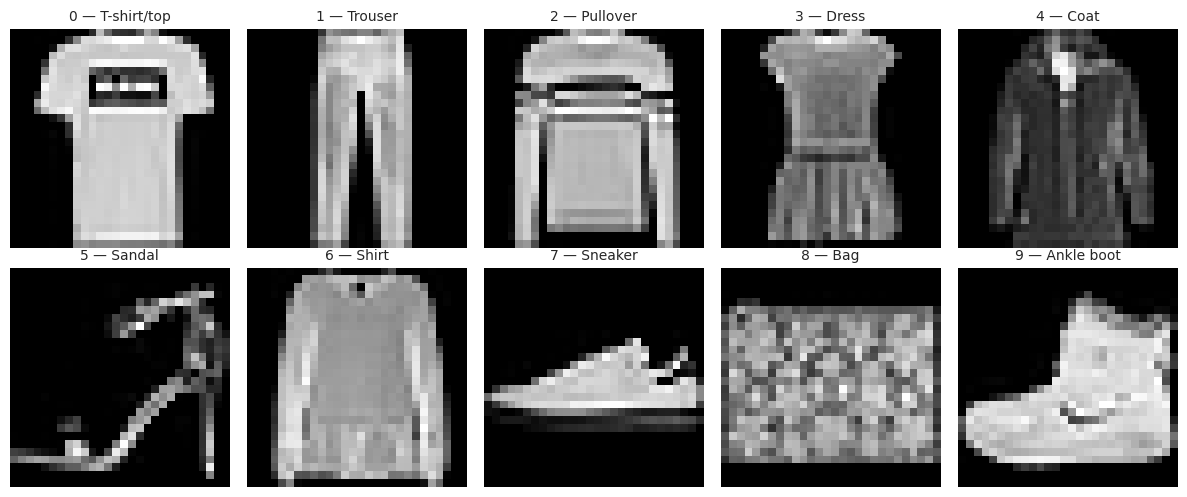

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == i)[0][0]
    ax.imshow(x_train_full[idx], cmap='gray')
    ax.set_title(f"{i} — {CLASES[i]}", fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Qué significa:** los zapatos y el bolso tienen siluetas muy distintas al resto. En cambio, las cuatro prendas de la parte de arriba del cuerpo (polera, pullover, abrigo y camisa) se parecen mucho: todas son un rectángulo con mangas. Nuestra hipótesis es que ahí van a estar los errores del modelo, y más adelante lo comprobamos.

### 2.4 Normalizar

**Qué hace el código:** divide todos los píxeles por 255, para que pasen de estar entre 0 y 255 a estar entre 0 y 1. También los convierte a números decimales (`float32`).

**Por qué normalizamos:**

- Con valores de hasta 255, las sumas que hace la primera capa dan números enormes. Eso desbalancea el gradiente (la señal que le indica a la red cómo corregirse) y el entrenamiento zigzaguea en vez de avanzar directo hacia el mínimo.
- Además, algunas funciones de activación (como sigmoide y tanh) se "aplanan" cuando reciben números muy grandes. Al aplanarse, su derivada se acerca a cero y el gradiente casi desaparece. Eso se llama **desvanecimiento del gradiente**.

**Por qué dividimos y no estandarizamos:** estandarizar (restar la media y dividir por la desviación estándar) sirve cuando las variables están en escalas distintas, por ejemplo edad y sueldo. Aquí las 784 variables son píxeles del mismo tipo y con el mismo rango, así que no hay escalas que emparejar: solo hay que achicar la magnitud. Además, como dividimos por una constante conocida (255), no calculamos nada a partir de los datos de entrenamiento, y por lo tanto no hay riesgo de **fuga de datos** (que información del conjunto de prueba se cuele en el entrenamiento).

In [ ]:
x_train_full_norm = x_train_full.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

print("Rango después de normalizar:", x_train_full_norm.min(), "-", x_train_full_norm.max())

Rango después de normalizar: 0.0 - 1.0


### 2.5 Separar validación

**Qué hace el código:** aparta el 10% del conjunto de entrenamiento (6.000 imágenes) para usarlo como validación, así que quedan 54.000 imágenes para entrenar. Además guarda una copia sin normalizar, cortada exactamente igual, que usamos en el experimento de la sección 2.6.

**Para qué sirve cada conjunto** (piensa en estudiar, dar un ensayo y rendir la prueba final):

- **Entrenamiento (54.000):** es lo que la red usa para ajustar sus pesos. Es como estudiar la materia.
- **Validación (6.000):** se mira *durante* el entrenamiento para decidir cuándo cortar y qué configuración conviene. Es como el ensayo.
- **Prueba (10.000):** la red nunca la usa para entrenar, y sirve para medir qué tan bien funciona con datos nuevos. Como la validación se usa para tomar decisiones, sus resultados quedan algo optimistas; el test es la medida más honesta, porque la red nunca lo vio.

In [ ]:
n_val = int(len(x_train_full_norm) * VAL_SPLIT)

x_val, y_val = x_train_full_norm[:n_val], y_train_full[:n_val]
x_train, y_train = x_train_full_norm[n_val:], y_train_full[n_val:]

# Copia sin normalizar, con el mismo corte, para medir el efecto de normalizar
x_val_crudo = x_train_full[:n_val].astype('float32')
x_train_crudo = x_train_full[n_val:].astype('float32')

if MODO_RAPIDO:
    x_train, y_train = x_train[:12000], y_train[:12000]
    x_train_crudo = x_train_crudo[:12000]
    EPOCAS_EXPERIMENTO, EPOCAS_FINAL = 6, 12
    print(">>> MODO_RAPIDO activo: resultados NO representativos <<<\n")

print("Entrenamiento:", x_train.shape)
print("Validación:   ", x_val.shape)
print("Prueba:       ", x_test_norm.shape)

Entrenamiento: (54000, 28, 28)
Validación:    (6000, 28, 28)
Prueba:        (10000, 28, 28)


### 2.6 ¿Cuánto importa normalizar?

**Qué hace el código:** en vez de suponer que normalizar ayuda, lo medimos. Entrenamos dos veces el mismo modelo chico (una capa oculta de 128 neuronas), con la misma semilla, cambiando una sola cosa: en un caso las imágenes van sin normalizar (0 a 255) y en el otro normalizadas (0 a 1). Después graficamos el accuracy y el loss de validación de cada uno para compararlos.

In [ ]:
def modelo_simple():
    fijar_semillas()
    return keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ])


historiales_norm = {}
for etiqueta, tr, va in [("Sin normalizar", x_train_crudo, x_val_crudo),
                         ("Normalizado", x_train, x_val)]:
    m = modelo_simple()
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(tr, y_train, validation_data=(va, y_val),
              epochs=10, batch_size=BATCH_SIZE, verbose=0)
    historialesnorm[etiqueta] = h
    print(f"{etiqueta:16s} | accuracy validación: {h.history['val_accuracy'][-1]:.4f}")

Sin normalizar   | accuracy validación: 0.8287
Normalizado      | accuracy validación: 0.8793


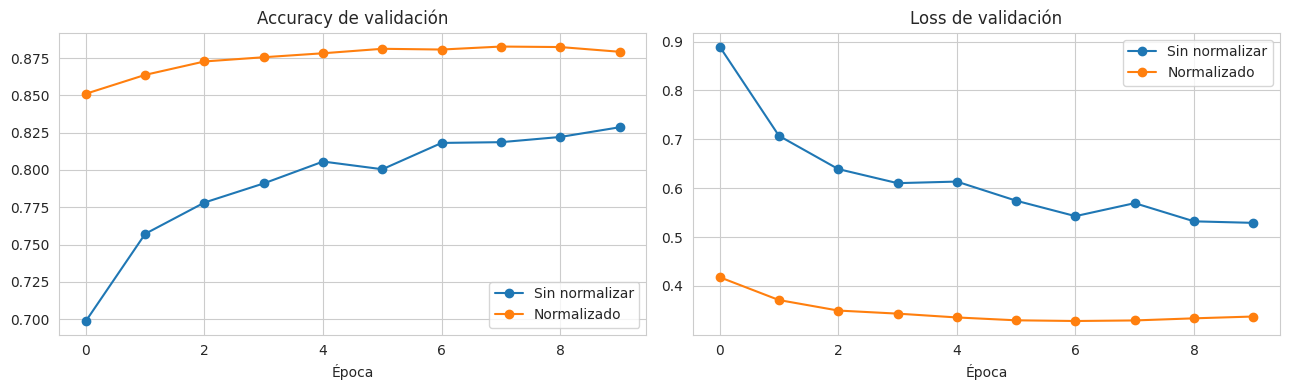

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for etiqueta, h in historiales_norm.items():
    axes[0].plot(h.history['val_accuracy'], marker='o', label=etiqueta)
    axes[1].plot(h.history['val_loss'], marker='o', label=etiqueta)
axes[0].set_title('Accuracy de validación'); axes[0].set_xlabel('Época'); axes[0].legend()
axes[1].set_title('Loss de validación'); axes[1].set_xlabel('Época'); axes[1].legend()
plt.tight_layout()
plt.show()

**Resultado:** el modelo normalizado llegó a un accuracy de validación de **0,8793**, contra **0,8287** del modelo sin normalizar. La diferencia se nota desde el comienzo: en la primera época el normalizado ya está cerca del 85%, mientras que el otro parte cerca del 70%. Además, la curva del modelo sin normalizar sube más despacio y tiene pequeños retrocesos, algo que suele indicar que los pasos de actualización le quedan demasiado grandes.

**Qué significa:** normalizar no es un simple trámite. Con el mismo modelo, los mismos datos y la misma semilla, solo por dividir por 255 se ganan unos 5 puntos de accuracy y un entrenamiento más estable.

## 3. Definición del modelo

### 3.1 La arquitectura

**Qué hace el código:** define la función `construir_mlp()`, que arma la red. Todos sus parámetros (activación, capas ocultas, dropout, etc.) vienen con los valores del **modelo base**. Así, en cada experimento cambiamos solo uno y dejamos el resto igual, y eso es lo que hace que los experimentos sean comparables. Al final imprime un resumen (`summary()`) con las capas y la cantidad de parámetros.

**La red, capa por capa:**

1. **Entrada (784):** la imagen de 28×28 se aplana en una fila de 28 × 28 = 784 números.
2. **Capa densa de 256 neuronas.**
3. **Capa densa de 128 neuronas.**
4. **Salida (10):** una neurona por cada categoría.

Una capa **densa** es aquella en la que cada neurona está conectada con todas las neuronas de la capa anterior.

**Por qué dos capas ocultas:** con una sola, la red solo puede hacer combinaciones simples de los píxeles. Con dos puede *componer*: la primera capa detecta patrones básicos y la segunda los junta para formar algo más complejo.

**Por qué no más:** probamos con tres y cuatro capas y el resultado en test no mejoró; solo subieron el tiempo de entrenamiento y el sobreajuste.

**Por qué 256 y 128:** la red se va achicando hacia la decisión final, como un embudo. Partimos con muchas neuronas para captar muchos detalles y vamos resumiendo hasta quedarnos con 10 respuestas.

In [ ]:
def construir_mlp(activacion='relu', capas_ocultas=(256, 128), dropout=0.0,
                  l2_lambda=0.0, batch_norm=False, activacion_salida='softmax'):
    """Arma el MLP. Cada parámetro permite variar un factor a la vez."""
    fijar_semillas()   # todos parten con los mismos pesos

    regularizador = keras.regularizers.l2(l2_lambda) if l2_lambda > 0 else None

    modelo = keras.Sequential()
    modelo.add(layers.Input(shape=(28, 28)))
    modelo.add(layers.Flatten())          # 28x28 -> vector de 784

    for unidades in capas_ocultas:
        # Dense y Activation van separados para poder meter BatchNorm en medio
        modelo.add(layers.Dense(unidades, kernel_regularizer=regularizador))
        if batch_norm:
            modelo.add(layers.BatchNormalization())
        modelo.add(layers.Activation(activacion))
        if dropout > 0:
            modelo.add(layers.Dropout(dropout))

    modelo.add(layers.Dense(10, activation=activacion_salida))
    return modelo


construir_mlp().summary()

**Resultado:** la red tiene alrededor de 235.000 parámetros entrenables (los pesos y sesgos que se ajustan durante el entrenamiento).

**Nota sobre el aplanado:** al convertir la imagen en una fila de 784 números se pierde la estructura espacial. Para la red, el píxel 400 y el píxel 401 son dos variables sin relación, aunque en la imagen estén uno al lado del otro. Esto explica el límite de desempeño que encontramos al final.

### 3.2 Las tres funciones

Son tres cosas distintas que conviene no confundir: la activación de las capas ocultas, la función de salida y la función de pérdida.

**Activación de las capas ocultas: ReLU**, que es `max(0, u)`: si el número es negativo lo deja en 0, y si es positivo lo deja igual.

Sirve para que la red pueda aprender relaciones que no son líneas rectas. La elegimos porque su derivada vale 1 en todo el lado positivo, así que al retropropagar (llevar el error hacia atrás para corregir los pesos) el gradiente pasa entero. La sigmoide, en cambio, tiene derivada máxima de 0,25 y se aplana en los extremos: al multiplicar esas derivadas capa por capa, el gradiente se va achicando hasta desvanecerse.

**Función de salida: Softmax.**

Toma las 10 salidas de la red y las transforma para que todas queden entre 0 y 1 y sumen exactamente 1; es decir, las convierte en probabilidades (por ejemplo: 90% zapatilla, 7% botín, 3% sandalia). Corresponde usarla porque las clases son excluyentes: una prenda es un zapato o una camisa, no las dos a la vez.

**Función de pérdida: Sparse Categorical Crossentropy.**

Es la "nota de error" que la red intenta bajar: mide qué tan lejos está la distribución de probabilidades que predijo de la distribución real (que es 100% en la clase correcta). Usamos la versión *sparse* porque nuestras etiquetas son números enteros del 0 al 9, y así no hay que convertirlas a one-hot (un vector de 10 posiciones con un 1 en la clase correcta). Es la misma pérdida; solo cambia el formato en que recibe las etiquetas.

---
# 🎤 Persona 2 — Experimentos
**Tiempo:** 3:20 a 6:40 · **Sección:** 4

**Qué tiene que quedar claro:**

- Cada experimento cambia **un solo factor** y usa la misma semilla. Hay que decirlo explícitamente, porque eso es lo que hace válida la comparación.
- El learning rate es el que más manda: mostrar el gráfico de la sección 4.5.
- ReLU converge más rápido que sigmoide por el desvanecimiento del gradiente (la sigmoide va achicando el gradiente capa tras capa).

**Ojo con el tiempo:** son cinco experimentos en poco más de tres minutos, o sea unos 40 segundos cada uno. No leer las tablas: decir cuál ganó y por qué.

**Para pasar la palabra:** *"Con la configuración elegida, [Persona 3] va a mostrar qué tan bien funciona y cómo lo mejoramos."*

**Preguntas probables del profesor:**

- *¿Por qué Adam si RMSProp da parecido?* → Porque Adam es menos sensible al learning rate, que es el hiperparámetro más difícil de ajustar. Si nos equivocamos un poco con el learning rate, Adam lo tolera mejor.
- *¿Qué diferencia hay entre época e iteración?* → Una época es pasar por todos los datos de entrenamiento una vez; una iteración es una sola actualización de los pesos (con un batch). Lo que realmente importa son las iteraciones del descenso del gradiente, porque en cada una se corrige la red.
- *¿Por qué fijan la semilla antes de cada modelo?* → Para que todos partan con los mismos pesos iniciales y la diferencia sea solo del parámetro que cambiamos, no del azar.

---

## 4. Entrenamiento y ajuste de hiperparámetros

Esta es la sección de experimentos. La idea es simple: partimos de un modelo base y, en cada experimento, cambiamos **un solo hiperparámetro** para ver cuánto influye. Como todos usan los mismos datos y la misma semilla, lo que cambie en el resultado se debe a ese parámetro.

### 4.1 Funciones de apoyo

**Qué hace el código:** define cuatro cosas que usamos en todos los experimentos, para no repetir código.

- `REGISTRO`: una lista donde se va guardando el resultado de cada configuración. Gracias a esto, la tabla comparativa del final se arma sola.
- `evaluar_en_test()`: mide el accuracy y el F1 macro de un modelo sobre el conjunto de prueba. (F1 macro es el promedio simple de los F1 de las 10 clases.)
- `entrenar()`: entrena un modelo, lo evalúa en test y anota el resultado en `REGISTRO`. También calcula la **brecha**, que es el accuracy de entrenamiento menos el de test: si es grande, la red memorizó parte de los ejemplos.
- `graficar_historial()`: dibuja las curvas de entrenamiento (línea llena) y de validación (línea punteada) época a época.

**Un detalle importante:** cuando se usa Early Stopping (una técnica que corta el entrenamiento a tiempo; la vemos en la sección 6), los valores de entrenamiento y validación que se anotan son los de la *mejor* época, no los de la última. Si usáramos los de la última, la brecha saldría inflada.

In [ ]:
REGISTRO = []


def evaluar_en_test(modelo):
    """Accuracy y F1 macro sobre el conjunto de prueba."""
    y_pred = np.argmax(modelo.predict(x_test_norm, verbose=0), axis=1)
    acc = accuracy_score(y_test, y_pred)
    _, _, f1, _ = precision_recall_fscore_support(y_test, y_pred,
                                                  average='macro', zero_division=0)
    return acc, f1, y_pred


def entrenar(nombre, modelo, optimizador=None, perdida='sparse_categorical_crossentropy',
             epocas=None, batch_size=None, callbacks=None,
             y_tr=None, y_va=None, grupo="", verbose=0):
    """Entrena, evalúa y guarda el resultado en REGISTRO."""
    epocas = epocas or EPOCAS_EXPERIMENTO
    batch_size = batch_size or BATCH_SIZE
    optimizador = optimizador or keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    y_tr = y_train if y_tr is None else y_tr
    y_va = y_val if y_va is None else y_va

    modelo.compile(optimizer=optimizador, loss=perdida, metrics=['accuracy'])

    t0 = time.time()
    hist = modelo.fit(x_train, y_tr, validation_data=(x_val, y_va),
                      epochs=epocas, batch_size=batch_size,
                      callbacks=callbacks, verbose=verbose)
    duracion = time.time() - t0
    epocas_corridas = len(hist.history['loss'])

    acc_test, f1_test, _ = evaluar_en_test(modelo)

    # Ojo: con Early Stopping los pesos que quedan son los de la MEJOR época,
    # no los de la última. Si usáramos la última, la brecha saldría inflada.
    idx = int(np.argmin(hist.history['val_loss'])) if callbacks else epocas_corridas - 1
    acc_train = hist.history['accuracy'][idx]
    acc_val = hist.history['val_accuracy'][idx]

    REGISTRO.append({
        'Grupo': grupo, 'Configuración': nombre,
        'Train': round(acc_train, 4), 'Validación': round(acc_val, 4),
        'Test': round(acc_test, 4), 'F1 macro': round(f1_test, 4),
        'Brecha': round(acc_train - acc_test, 4),
        'Épocas': epocas_corridas, 'Seg./época': round(duracion / epocas_corridas, 1),
    })

    print(f"{nombre:34s} | test {acc_test:.4f} | F1 {f1_test:.4f} | "
          f"brecha {acc_train - acc_test:+.4f}")
    return hist, acc_test, f1_test


def graficar_historial(historiales, titulo, metrica='accuracy'):
    """Curvas de train (línea llena) y validación (punteada)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for etiqueta, h in historiales.items():
        axes[0].plot(h.history[metrica], label=f'{etiqueta} (train)')
        axes[0].plot(h.history[f'val_{metrica}'], linestyle='--', label=f'{etiqueta} (val)')
        axes[1].plot(h.history['val_loss'], label=etiqueta)
    axes[0].set_title(metrica.capitalize()); axes[0].set_xlabel('Época'); axes[0].legend(fontsize=8)
    axes[1].set_title('Loss de validación'); axes[1].set_xlabel('Época'); axes[1].legend(fontsize=8)
    plt.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()

### 4.2 Modelo base

**Qué hace el código:** entrena la configuración de referencia: activación ReLU, optimizador Adam, learning rate 0,001, batch de 64 imágenes, 15 épocas y sin regularización. En la celda siguiente graficamos cómo evolucionan el accuracy y el loss.

Estos valores son solo un punto de partida; todavía no los elegimos como definitivos. Cada uno se compara con alternativas en su propio experimento más abajo.

**Palabras que vamos a usar mucho:**

- **Época:** una pasada completa por todos los datos de entrenamiento.
- **Batch:** el grupo de imágenes que la red mira antes de corregir sus pesos una vez (aquí, 64).
- **Learning rate:** el tamaño del paso con que la red corrige sus pesos en cada actualización.
- **Optimizador:** el algoritmo que decide cómo se usan los gradientes para actualizar los pesos (aquí, Adam).

In [ ]:
modelo_base = construir_mlp()
hist_base, acc_base, f1_base = entrenar("Base (ReLU + Adam + lr 0.001)",
                                        modelo_base, grupo="Base", verbose=2)

In [ ]:
graficar_historial({'Modelo base': hist_base}, 'Modelo base')

**Resultado:** las curvas de entrenamiento y de validación se separan a partir de cierta época. El accuracy de entrenamiento sigue subiendo, pero el de validación se queda casi pegado.

**Qué significa:** eso es **sobreajuste**. La red memoriza los ejemplos de entrenamiento en vez de aprender el patrón general, por eso rinde muy bien con lo que ya vio y no mejora con datos nuevos. Lo dejamos así a propósito, porque necesitamos un modelo de referencia sin regularizar para medir después cuánto aporta cada técnica.

### 4.3 Experimento A: funciones de activación

**Qué hace el código:** entrena tres modelos cambiando solo la función de activación (ReLU, tanh y sigmoide). Todo lo demás queda idéntico, incluida la semilla. Después grafica las curvas, calcula en qué época cada uno llega al 85% de accuracy en validación y muestra una tabla con train, test y F1.

In [ ]:
historiales_act = {}
for act in ['relu', 'tanh', 'sigmoid']:
    m = construir_mlp(activacion=act)
    h, _, _ = entrenar(f"Activación: {act}", m, grupo="Activación")
    historiales_act[act] = h

In [ ]:
graficar_historial(historiales_act, 'Funciones de activación')

print("\nÉpocas para llegar a 85% de accuracy en validación:")
for act, h in historiales_act.items():
    sup = np.where(np.array(h.history['val_accuracy']) >= 0.85)[0]
    print(f"  {act:8s}: {sup[0] + 1 if len(sup) else 'no alcanzado'}")

display(pd.DataFrame([r for r in REGISTRO if r['Grupo'] == 'Activación'])
        [['Configuración', 'Train', 'Test', 'F1 macro']])

**Resultado:** *(completar)*. La diferencia grande no está en el accuracy final sino en la velocidad: ReLU cruza el 85% varias épocas antes que sigmoide.

**Por qué pasa:**

1. La derivada de la sigmoide vale como máximo 0,25 y se acerca a cero en los extremos.
2. Al retropropagar, el gradiente que llega a la primera capa es el *producto* de las derivadas de todas las capas siguientes.
3. Multiplicar números menores que 1 una y otra vez los hace cada vez más chicos, así que con sigmoide el gradiente se va achicando. Con ReLU la derivada es 1 y el gradiente llega entero.

Con solo dos capas ocultas el efecto es moderado. En una red de veinte capas el entrenamiento se pararía casi por completo.

### 4.4 Experimento B: función de pérdida

**Qué hace el código:** compara crossentropy contra MSE (error cuadrático medio). MSE necesita que las etiquetas estén en formato one-hot, así que las convertimos solo para ese caso (`to_categorical`). Después grafica el accuracy de validación de ambos.

In [ ]:
y_train_oh = keras.utils.to_categorical(y_train, 10)
y_val_oh = keras.utils.to_categorical(y_val, 10)

historiales_perdida = {}

m = construir_mlp()
historiales_perdida['Crossentropy'] = entrenar("Pérdida: crossentropy", m, grupo="Pérdida")[0]

m = construir_mlp()
historiales_perdida['MSE'] = entrenar("Pérdida: MSE", m, perdida='mse',
                                      y_tr=y_train_oh, y_va=y_val_oh, grupo="Pérdida")[0]

In [ ]:
# Comparamos accuracy y no loss: los dos loss miden cosas distintas
plt.figure(figsize=(7, 4.5))
for etiqueta, h in historiales_perdida.items():
    plt.plot(h.history['val_accuracy'], marker='o', markersize=3, label=etiqueta)
plt.xlabel('Época'); plt.ylabel('Accuracy de validación')
plt.title('Crossentropy contra MSE'); plt.legend()
plt.tight_layout(); plt.show()

**Resultado:** crossentropy converge más rápido y termina mejor. Para compararlas usamos el accuracy y no el loss, porque cada pérdida mide algo distinto (tienen escalas diferentes) y no se pueden comparar directamente.

**Por qué pasa:**

- Con crossentropy, cuando el modelo le asigna una probabilidad muy baja a la clase correcta, el término −log(ŷ) se dispara y produce una corrección grande. Es decir, castiga fuerte los errores graves.
- Con MSE ocurre lo contrario: el gradiente se hace chico justo cuando la predicción está más equivocada, así que corrige lento.
- Además, en clasificación queremos medir la distancia entre distribuciones de probabilidad, y eso es la entropía cruzada. MSE mide distancia euclidiana, que sirve más en regresión (predecir un número, como un precio).

### 4.5 Experimento C: learning rate

**Qué hace el código:** entrena el mismo modelo con cuatro learning rates: 0,1; 0,01; 0,001 y 0,0001. Recuerda que el learning rate es el tamaño de cada paso de corrección: si es muy grande, la red se pasa de largo; si es muy chico, avanza casi nada. El gráfico muestra el loss de validación de cada uno.

In [ ]:
historiales_lr = {}
for lr in [0.1, 0.01, 0.001, 0.0001]:
    m = construir_mlp()
    h, _, _ = entrenar(f"Learning rate: {lr}", m,
                       optimizador=keras.optimizers.Adam(learning_rate=lr),
                       grupo="Learning rate")
    historiales_lr[f"lr={lr}"] = h

In [ ]:
plt.figure(figsize=(8, 4.5))
for etiqueta, h in historiales_lr.items():
    plt.plot(h.history['val_loss'], marker='o', markersize=3, label=etiqueta)
plt.xlabel('Época'); plt.ylabel('Loss de validación')
plt.title('Efecto del learning rate'); plt.legend()
plt.tight_layout(); plt.show()

**Resultado:** el gráfico reproduce la figura del PPT del curso. Con cada valor pasa lo siguiente:

- **0,1** → el loss sube o queda errático. Los pasos son tan grandes que la red pasa por encima del mínimo una y otra vez, sin asentarse nunca.
- **0,01** → el loss baja rápido al principio, pero después se queda pegado en un valor peor, probablemente porque los pasos todavía son grandes para afinar la solución.
- **0,001** → baja de forma suave y llega al valor más bajo. **Es el que elegimos.**
- **0,0001** → baja bien, pero tan lento que en 15 épocas no alcanza a converger. Los pasos son demasiado chicos.

**Qué significa:** es el hiperparámetro que más influye. Un valor mal elegido puede impedir del todo que la red aprenda, mientras que los demás producen diferencias más graduales.

### 4.6 Experimento D: tamaño del batch

**Qué hace el código:** entrena con tres tamaños de batch (16, 64 y 256 imágenes por actualización) y mide también cuánto demora cada época. Recuerda que el batch es el grupo de imágenes que la red mira antes de corregir sus pesos una vez.

In [ ]:
historiales_batch = {}
for bs in [16, 64, 256]:
    m = construir_mlp()
    h, _, _ = entrenar(f"Batch size: {bs}", m, batch_size=bs, grupo="Batch size")
    historiales_batch[f"batch={bs}"] = h

display(pd.DataFrame([r for r in REGISTRO if r['Grupo'] == 'Batch size'])
        [['Configuración', 'Test', 'F1 macro', 'Seg./época']])

**Resultado:** el accuracy final casi no cambia entre los tres tamaños de batch, pero sí cambia el tiempo que demora cada época.

**Qué significa:** hay un compromiso entre precisión y velocidad.

- **Batch chico (16):** hace muchas más actualizaciones por época, pero cada una usa pocas imágenes, así que el gradiente es más ruidoso (menos preciso) y la época demora más.
- **Batch grande (256):** cada época es más rápida y más estable, pero hace menos actualizaciones, así que avanza menos por época.
- **Batch mediano (64):** es el punto medio y el que elegimos.

Esto conecta con la idea del PPT de que lo que importa no son las épocas, sino las iteraciones (las actualizaciones) del descenso del gradiente.

### 4.7 Experimento E: optimizadores

**Qué hace el código:** compara cuatro algoritmos de optimización: SGD, SGD con Momentum, RMSProp y Adam. Un optimizador es la "receta" que decide cómo se usan los gradientes para actualizar los pesos. Ojo con un detalle: SGD y SGD + Momentum usan learning rate 0,01, mientras que RMSProp y Adam usan 0,001, el valor de nuestro modelo base.

In [ ]:
historiales_opt = {}
optimizadores = {
    'SGD': keras.optimizers.SGD(learning_rate=0.01),
    'SGD + Momentum': keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'RMSProp': keras.optimizers.RMSprop(learning_rate=LEARNING_RATE),
    'Adam': keras.optimizers.Adam(learning_rate=LEARNING_RATE),
}

for nombre_opt, opt in optimizadores.items():
    m = construir_mlp()
    h, _, _ = entrenar(f"Optimizador: {nombre_opt}", m, optimizador=opt, grupo="Optimizador")
    historiales_opt[nombre_opt] = h

In [ ]:
plt.figure(figsize=(8, 4.5))
for etiqueta, h in historiales_opt.items():
    plt.plot(h.history['val_accuracy'], marker='o', markersize=3, label=etiqueta)
plt.xlabel('Época'); plt.ylabel('Accuracy de validación')
plt.title('Optimizadores'); plt.legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame([r for r in REGISTRO if r['Grupo'] == 'Optimizador'])
        [['Configuración', 'Train', 'Test', 'F1 macro', 'Brecha']])

**Qué hace cada uno:**

- **SGD** (descenso del gradiente estocástico): usa el mismo learning rate para todos los parámetros. Funciona, pero converge lento.
- **SGD + Momentum:** además guarda memoria de los gradientes anteriores, como una pelota que va tomando velocidad. Eso le ayuda a cruzar zonas planas y a zigzaguear menos.
- **RMSProp:** lleva un promedio móvil de los gradientes recientes (al cuadrado) y lo usa para adaptar el paso de cada parámetro: si un parámetro recibe gradientes grandes, da pasos más chicos.
- **Adam:** junta las dos ideas anteriores: la memoria de los gradientes pasados (β₁ = 0,9, que promedia el gradiente) y la adaptación por parámetro (β₂ = 0,999, que promedia su cuadrado, o sea la varianza). **Es el que elegimos.**

**Por qué Adam:** el resultado final queda parecido al de RMSProp, pero Adam es mucho menos sensible al learning rate, que es justo el hiperparámetro más difícil de ajustar a mano.

> Nota: el PPT dice β₂ = 0,99; el valor por defecto de Keras y del paper original de Adam es 0,999. Dejamos el de Keras.

---
# 🎤 Persona 3 — Resultados y mejora
**Tiempo:** 6:40 a 10:00 · **Secciones:** 5, 6 y 7

**Qué tiene que quedar claro:**

- El accuracy global esconde que la clase Shirt anda mal: mostrar la matriz de confusión.
- Al regularizar baja el accuracy de entrenamiento, y eso está bien (la red memoriza menos).
- Por qué elegimos el modelo final, y que el límite que queda es de arquitectura, no de entrenamiento.

**Ojo:** la matriz de confusión y el hallazgo de Shirt es lo que más puntaje tiene de toda la rúbrica. Vale la pena darle más tiempo que al resto.

**Para cerrar:** decir el accuracy final comparado con el benchmark (0,8833) y el desempeño humano (0,835), y ofrecer el notebook para preguntas.

**Preguntas probables del profesor:**

- *¿Por qué no eligieron el de mejor accuracy de entrenamiento?* → Porque es justamente el que más sobreajusta (memoriza). Lo que importa es el desempeño en test, que son datos que la red nunca vio.
- *¿Por qué no usaron una red convolucional?* → El alcance de la unidad es MLP. La dejamos identificada como la mejora siguiente, porque conserva la relación entre píxeles vecinos.
- *¿Qué diferencia hay entre precision y recall?* → Precision: de lo que predije como esta clase, cuánto acerté. Recall: de lo que realmente era esta clase, cuánto logré detectar.

---

## 5. Evaluación del modelo

Hasta ahora comparamos configuraciones con curvas y accuracy. En esta sección miramos el desempeño con más detalle, clase por clase, sobre el conjunto de prueba.

**Las cuatro métricas, en simple.** Para entenderlas, piensa en la clase "Shirt" (camisa):

- **Accuracy:** de *todas* las imágenes, qué porcentaje clasificó bien el modelo.
- **Precision:** de todas las imágenes que el modelo llamó "camisa", cuántas eran realmente camisas. Mide qué tan confiable es el modelo cuando dice "camisa".
- **Recall:** de todas las camisas que realmente había, cuántas logró encontrar el modelo. Mide cuántas se le escapan.
- **F1:** combina precision y recall en un solo número (media armónica). Solo es alto si las dos son altas: castiga que una de ellas sea baja.

**Qué hace el código:** predice sobre el conjunto de prueba (imágenes que la red nunca usó para entrenar) con el modelo base e imprime el reporte por clase. Luego ordena las clases por F1, para ver primero las problemáticas, y las grafica en barras con una línea que marca el F1 promedio (F1 macro).

In [ ]:
y_pred_base = np.argmax(modelo_base.predict(x_test_norm, verbose=0), axis=1)

print("Accuracy en test:", round(accuracy_score(y_test, y_pred_base), 4))
print("\n" + "="*70)
print(classification_report(y_test, y_pred_base, target_names=CLASES, digits=4))

In [ ]:
# Ordenamos por F1 para ver al tiro las clases problemáticas
p, r, f1, soporte = precision_recall_fscore_support(y_test, y_pred_base, zero_division=0)

tabla_metricas = pd.DataFrame({
    'Clase': CLASES, 'Precision': p.round(4), 'Recall': r.round(4), 'F1': f1.round(4)
}).sort_values('F1')
display(tabla_metricas)

plt.figure(figsize=(9, 4.5))
plt.barh(tabla_metricas['Clase'], tabla_metricas['F1'], color='#3B6EA5')
plt.axvline(f1.mean(), color='#D7263D', linestyle='--', label=f'F1 macro = {f1.mean():.3f}')
plt.xlabel('F1-score'); plt.title('F1 por clase'); plt.legend()
plt.tight_layout(); plt.show()

**Qué hace el código:** dibuja la **matriz de confusión** y lista los cinco pares de clases que más se confunden.

Cómo se lee la matriz: cada fila es la clase real y cada columna es lo que predijo el modelo. La diagonal son los aciertos. Todo lo que queda fuera de la diagonal son errores, y cada celda dice *con qué* clase se está confundiendo el modelo.

In [ ]:
cm = confusion_matrix(y_test, y_pred_base)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASES, yticklabels=CLASES)
plt.xlabel('Predicción'); plt.ylabel('Valor real')
plt.title('Matriz de confusión — modelo base')
plt.tight_layout(); plt.show()

cm_sin_diagonal = cm.copy()
np.fill_diagonal(cm_sin_diagonal, 0)
print("Confusiones más frecuentes:")
for _ in range(5):
    i, j = np.unravel_index(cm_sin_diagonal.argmax(), cm_sin_diagonal.shape)
    print(f"  {cm_sin_diagonal[i, j]:4d} casos: '{CLASES[i]}' clasificado como '{CLASES[j]}'")
    cm_sin_diagonal[i, j] = 0

### Qué nos dicen los resultados

*(Ajustar a los números de la corrida.)*

**El accuracy global esconde información.** El promedio se ve bien, pero al abrirlo por clase el desempeño es muy desparejo: algunas clases andan muy bien y otras claramente peor. Este es el mejor argumento de por qué no basta con una sola métrica, incluso cuando las clases están balanceadas.

**Dónde falla:** la clase Shirt tiene el F1 más bajo de las diez. Se confunde con T-shirt/top, Pullover y Coat. Es justo lo que anticipamos al mirar las imágenes en la sección 2.3.

**Dónde anda bien:** Trouser, Bag y los tres tipos de calzado (Sandal, Sneaker y Ankle boot), porque sus siluetas no se parecen a ninguna otra clase.

**Qué significa el recall bajo en Shirt:** muchas camisas reales se están yendo a otras categorías. Si el modelo se usara para catalogar un inventario, la categoría "camisas" quedaría con menos productos de los que le corresponden.

**La causa:** las cuatro prendas de arriba se diferencian por detalles chicos y locales (botones, cuello, textura). La red recibe la imagen aplanada, así que no puede representar la relación entre píxeles vecinos y no logra "ver" esos detalles.

## 6. Análisis y mejora

### 6.1 Las cuatro técnicas

El problema que detectamos en el modelo base es el sobreajuste. Estas cuatro técnicas ayudan a reducirlo:

**Dropout (0,3):** en cada batch "apaga" al azar el 30% de las neuronas (las ignora por ese paso). Así la red no puede depender de unas pocas neuronas y tiene que repartir lo que aprende.

**L2 (λ = 0,001):** le suma al error un castigo proporcional al tamaño de los pesos (λ·‖W‖², donde W son los pesos). Los pesos grandes salen "caros", entonces la red los mantiene chicos y reparte la decisión en vez de apoyarse en unos pocos pesos enormes.

**Batch Normalization:** normaliza la salida de cada capa usando la media y la varianza del batch. Eso estabiliza lo que recibe la capa siguiente y hace el entrenamiento más estable.

**Early Stopping:** vigila el error de validación y corta el entrenamiento cuando deja de mejorar, devolviendo los mejores pesos. Es como dejar de estudiar cuando ya no aprendes nada nuevo, antes de empezar a memorizar.

**Qué hace el código:** prueba primero Dropout, L2 y Batch Normalization por separado y después las tres juntas, siempre comparando contra el modelo base sin regularización. Early Stopping se agrega después, en el modelo final (sección 6.2).

In [ ]:
historiales_reg = {'Sin regularización': hist_base}

for nombre, params in [
    ("Dropout 0.3",              {"dropout": 0.3}),
    ("L2 (lambda=0.001)",        {"l2_lambda": 0.001}),
    ("Batch Normalization",      {"batch_norm": True}),
    ("Dropout + L2 + BatchNorm", {"dropout": 0.3, "l2_lambda": 0.001, "batch_norm": True}),
]:
    m = construir_mlp(**params)
    h, _, _ = entrenar(nombre, m, grupo="Regularización")
    historiales_reg[nombre] = h

In [ ]:
plt.figure(figsize=(9, 5))
for etiqueta, h in historiales_reg.items():
    plt.plot(h.history['val_accuracy'], label=etiqueta)
plt.xlabel('Época'); plt.ylabel('Accuracy de validación')
plt.title('Efecto de la regularización'); plt.legend(fontsize=9)
plt.tight_layout(); plt.show()

tabla_reg = pd.DataFrame([r for r in REGISTRO if r['Grupo'] in ('Base', 'Regularización')])
display(tabla_reg[['Configuración', 'Train', 'Test', 'Brecha', 'F1 macro']])

plt.figure(figsize=(9, 4))
plt.barh(tabla_reg['Configuración'], tabla_reg['Brecha'], color='#D7263D')
plt.xlabel('Brecha train − test')
plt.title('Sobreajuste (barra más corta = mejor)')
plt.tight_layout(); plt.show()

**Resultado que sorprende:** el accuracy de **entrenamiento baja** al regularizar.

**Qué significa:** está bien que baje, es justamente el objetivo. Estamos cambiando capacidad de memorizar por capacidad de generalizar (rendir bien con datos nuevos). Si el accuracy de entrenamiento no bajara, sería señal de que la técnica no está haciendo nada. Lo que hay que mirar es que el accuracy de **test** suba y que la **brecha** (train − test) se cierre.

### 6.2 Modelo final

**Qué hace el código:** combina las tres técnicas anteriores (Dropout + L2 + Batch Normalization) y les agrega Early Stopping. Entrena hasta un máximo de 50 épocas, pero Early Stopping puede cortar antes. Al final imprime en qué época se detuvo y de cuál época quedaron los pesos.

**Por qué esta configuración de Early Stopping:**

- **`val_loss` y no `val_accuracy`:** la pérdida empeora antes de que el accuracy lo refleje, así que avisa más temprano de que la red empezó a sobreajustar.
- **Paciencia 5:** espera cinco épocas seguidas sin mejora antes de cortar, para no detenerse por una subida puntual.
- **`restore_best_weights=True`:** al cortar, devuelve los pesos de la mejor época y no los de cinco épocas después, que ya venían empeorando.

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

modelo_final = construir_mlp(dropout=0.3, l2_lambda=0.001, batch_norm=True)
hist_final, acc_final, f1_final = entrenar(
    "FINAL: Dropout + L2 + BN + EarlyStopping", modelo_final,
    epocas=EPOCAS_FINAL, callbacks=[early_stopping], grupo="Final", verbose=2)

print(f"\nSe detuvo en la época {len(hist_final.history['loss'])} de {EPOCAS_FINAL}")
print(f"Quedaron los pesos de la época "
      f"{int(np.argmin(hist_final.history['val_loss'])) + 1}")

In [ ]:
graficar_historial({'Modelo final': hist_final}, 'Modelo final')

In [ ]:
y_pred_final = np.argmax(modelo_final.predict(x_test_norm, verbose=0), axis=1)

print(classification_report(y_test, y_pred_final, target_names=CLASES, digits=4))

plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASES, yticklabels=CLASES)
plt.xlabel('Predicción'); plt.ylabel('Valor real')
plt.title('Matriz de confusión — modelo final')
plt.tight_layout(); plt.show()

**Qué hace el código:** compara el F1 de cada clase entre el modelo base y el modelo final, ordenadas por cuánto mejoraron, y lo grafica en barras (gris = base, rojo = final). Sirve para ver *dónde* ayudó la regularización: si mejoró de forma pareja o si las clases difíciles, como Shirt, siguen casi igual.

In [ ]:
_, _, f1_b, _ = precision_recall_fscore_support(y_test, y_pred_base, zero_division=0)
_, _, f1_f, _ = precision_recall_fscore_support(y_test, y_pred_final, zero_division=0)

display(pd.DataFrame({
    'Clase': CLASES, 'F1 base': f1_b.round(4), 'F1 final': f1_f.round(4),
    'Diferencia': (f1_f - f1_b).round(4),
}).sort_values('Diferencia', ascending=False))

x = np.arange(len(CLASES))
plt.figure(figsize=(11, 4.5))
plt.bar(x - 0.2, f1_b, 0.4, label='Base', color='#9AA5B8')
plt.bar(x + 0.2, f1_f, 0.4, label='Final', color='#D7263D')
plt.xticks(x, CLASES, rotation=40, ha='right')
plt.ylabel('F1-score'); plt.title('F1 por clase: base contra final'); plt.legend()
plt.tight_layout(); plt.show()

### 6.3 Todas las configuraciones

**Qué hace el código:** arma una tabla con las 22 configuraciones que entrenamos (una fila por cada una, con train, validación, test, F1, brecha, épocas y segundos por época), la ordena de mayor a menor accuracy en test e imprime cuál fue la mejor según cada criterio. También la exporta a un archivo CSV por si queremos pegarla en la presentación.

In [ ]:
tabla_global = pd.DataFrame(REGISTRO)[['Grupo', 'Configuración', 'Train', 'Validación',
                                       'Test', 'F1 macro', 'Brecha', 'Épocas', 'Seg./época']]
display(tabla_global.sort_values('Test', ascending=False).reset_index(drop=True))

print("\nMejor test  :", tabla_global.loc[tabla_global['Test'].idxmax(), 'Configuración'])
print("Mejor F1    :", tabla_global.loc[tabla_global['F1 macro'].idxmax(), 'Configuración'])
print("Menor brecha:", tabla_global.loc[tabla_global['Brecha'].idxmin(), 'Configuración'])

tabla_global.to_csv('comparacion_configuraciones.csv', index=False)
print("\nTabla guardada como comparacion_configuraciones.csv")

**Por qué elegimos la configuración final**, en este orden de importancia:

1. **Mejor accuracy en test**, que es lo que estima el desempeño con datos nunca vistos.
2. **Menor brecha** entre entrenamiento y test: significa que lo aprendido sirve más allá de los ejemplos que la red vio.
3. **Mejor F1 macro:** muestra que el modelo también mejoró las clases difíciles y no solo las fáciles.

**Por qué no elegimos la de mejor accuracy de entrenamiento:** esa es justamente la que más sobreajusta, porque su nota alta viene de haber memorizado.

**Y tampoco basta con elegir solo la de menor brecha:** un modelo que aprende muy poco tendría una brecha casi cero (le va igual de mal en train y en test) y sería pésimo. Por eso el criterio que sirve es el que junta las dos cosas: buen test *y* poca brecha.

## 7. Conclusiones

**Resultados.** *(Completar.)* El modelo final llega a **[valor]** de accuracy y **[valor]** de F1 macro en test, partiendo de **[valor]** del modelo base. Como referencia, el benchmark oficial de un MLP es 0,8833 y el desempeño humano 0,835.

**Lo que aprendimos:**

- **Normalizar las imágenes tiene un efecto medible:** con el mismo modelo, el normalizado aprendió más rápido y de forma más estable (sección 2.6).
- **El learning rate es el hiperparámetro que más influye.** Un valor mal elegido puede impedir del todo que la red aprenda; el resto produce diferencias graduales.
- **La activación afecta sobre todo a la velocidad de convergencia**, no tanto al resultado final, en una red de dos capas ocultas.
- **La regularización funciona bajando el desempeño en entrenamiento.** Suena al revés, pero es el mecanismo: se cambia memorización por generalización.
- **El batch size pega más en el tiempo que en el resultado.**

**Lo que quedó pendiente.** La limitación principal no es de entrenamiento sino de arquitectura. La confusión entre camisa, polera, pullover y abrigo no se arregla con más épocas ni con más regularización, porque su causa es que al aplanar la imagen se pierde la estructura espacial.

En los términos del PPT, esto es un problema de **sesgo** (la red es demasiado limitada para representar bien el problema) y no de **varianza** (sobreajuste). La regularización ayuda a cerrar la brecha entre entrenamiento y test, pero no arregla lo que la arquitectura no es capaz de ver.

**La mejora que sigue** es una **red convolucional (CNN)**: en vez de aplanar la imagen, la recorre con filtros pequeños y así conserva la vecindad entre píxeles. De esa forma puede detectar los detalles locales (bordes, cuellos, botones) que distinguen esas cuatro clases. Los benchmarks reportan que las CNN pasan el 93% de accuracy, donde un MLP se queda cerca del 88%.